In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import os

In [2]:
bcalc_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results\Dataframes\Bcalc_8okt2026.xlsx"
bcalc_nocalc_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results\Dataframes\Bcalc_nocalc_8okt2026.xlsx"

df1 = pd.read_excel(bcalc_path)       # normal
df2 = pd.read_excel(bcalc_nocalc_path) # no calcification

In [4]:
### OUTPUT ###

output_dir = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results"
# file_name = "Bcalc_nocalc_comparison_8okt2026"

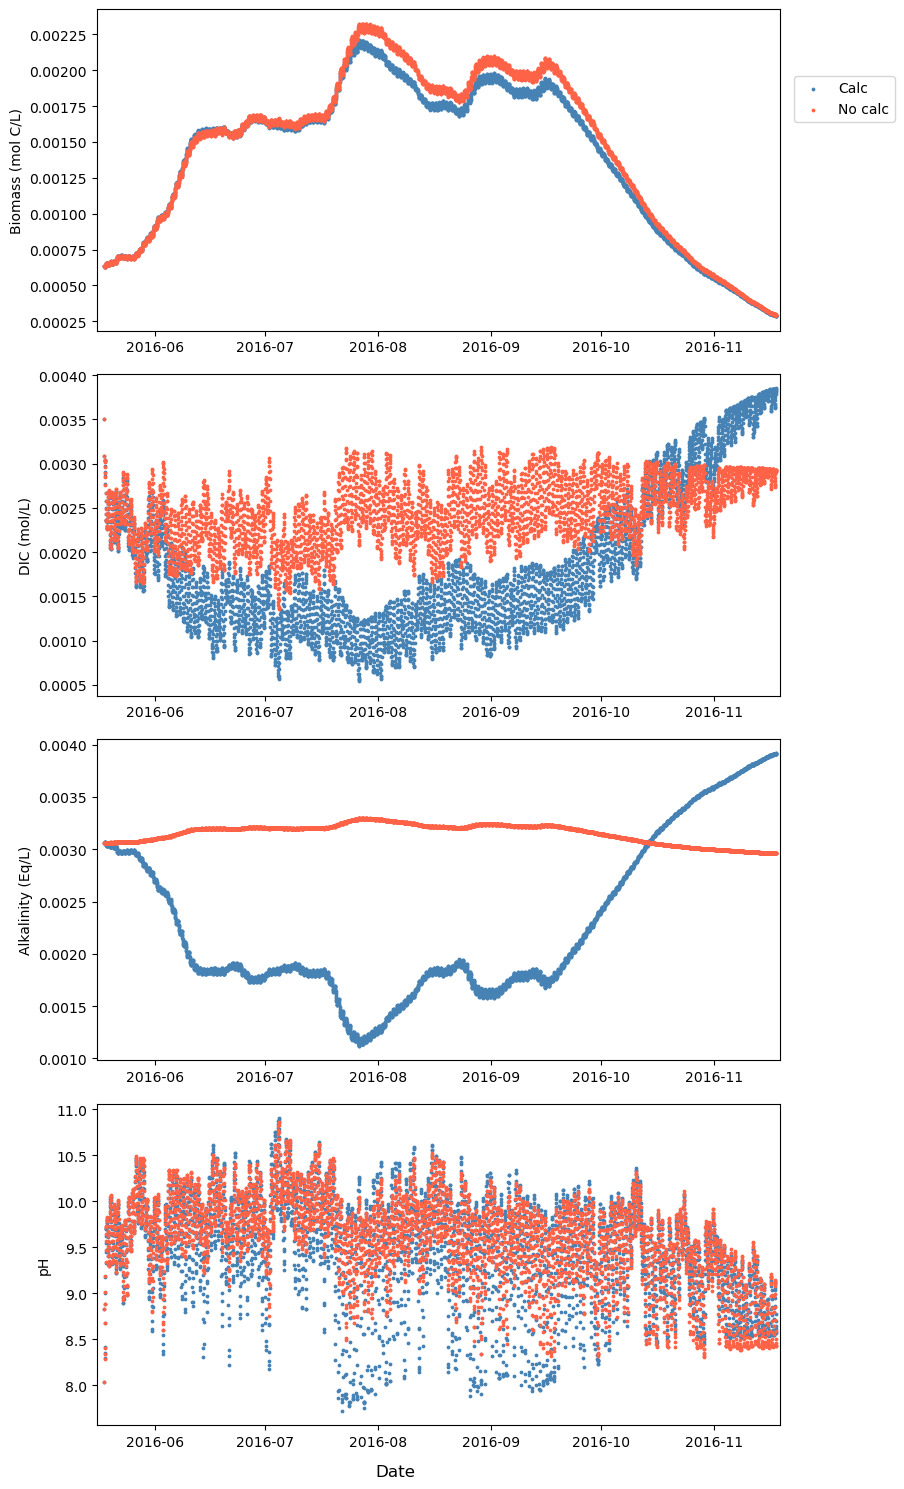

In [23]:
fig, axs = plt.subplots(4, figsize=(8, 15))

######## Biomass ########
axs[0].scatter(df1["date"], df1["B"], s=3, color="steelblue")
axs[0].scatter(df2["date"], df2["B"], s=3, color="tomato")
axs[0].set_ylabel('Biomass (mol C/L)')

######## DIC ########
axs[1].scatter(df1["date"], df1['DIC'], s=3, color="steelblue")
axs[1].scatter(df2['date'], df2['DIC'], s=3, color="tomato")
axs[1].set_ylabel('DIC (mol/L)')

######## Alkalinity ########
axs[2].scatter(df1["date"], df1['Alk'], s=3, color="steelblue")
axs[2].scatter(df2['date'], df2['Alk'], s=3, color="tomato")
axs[2].set_ylabel('Alkalinity (Eq/L)')

######## pH ########
axs[3].scatter(df1["date"], df1['pH'], s=3, color="steelblue")
axs[3].scatter(df2['date'], df2['pH'], s=3, color="tomato")
axs[3].set_ylabel('pH')


for ax in axs:
    ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))
    # ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-05-20"))
    
fig.legend(['Calc','No calc'], loc="upper left", bbox_to_anchor=(0.99, 0.95))
fig.supxlabel('Date')
plt.tight_layout()

##### Saving #####
out = os.path.join(output_dir, f"Plots\\{file_name}.png")
plt.savefig(out)

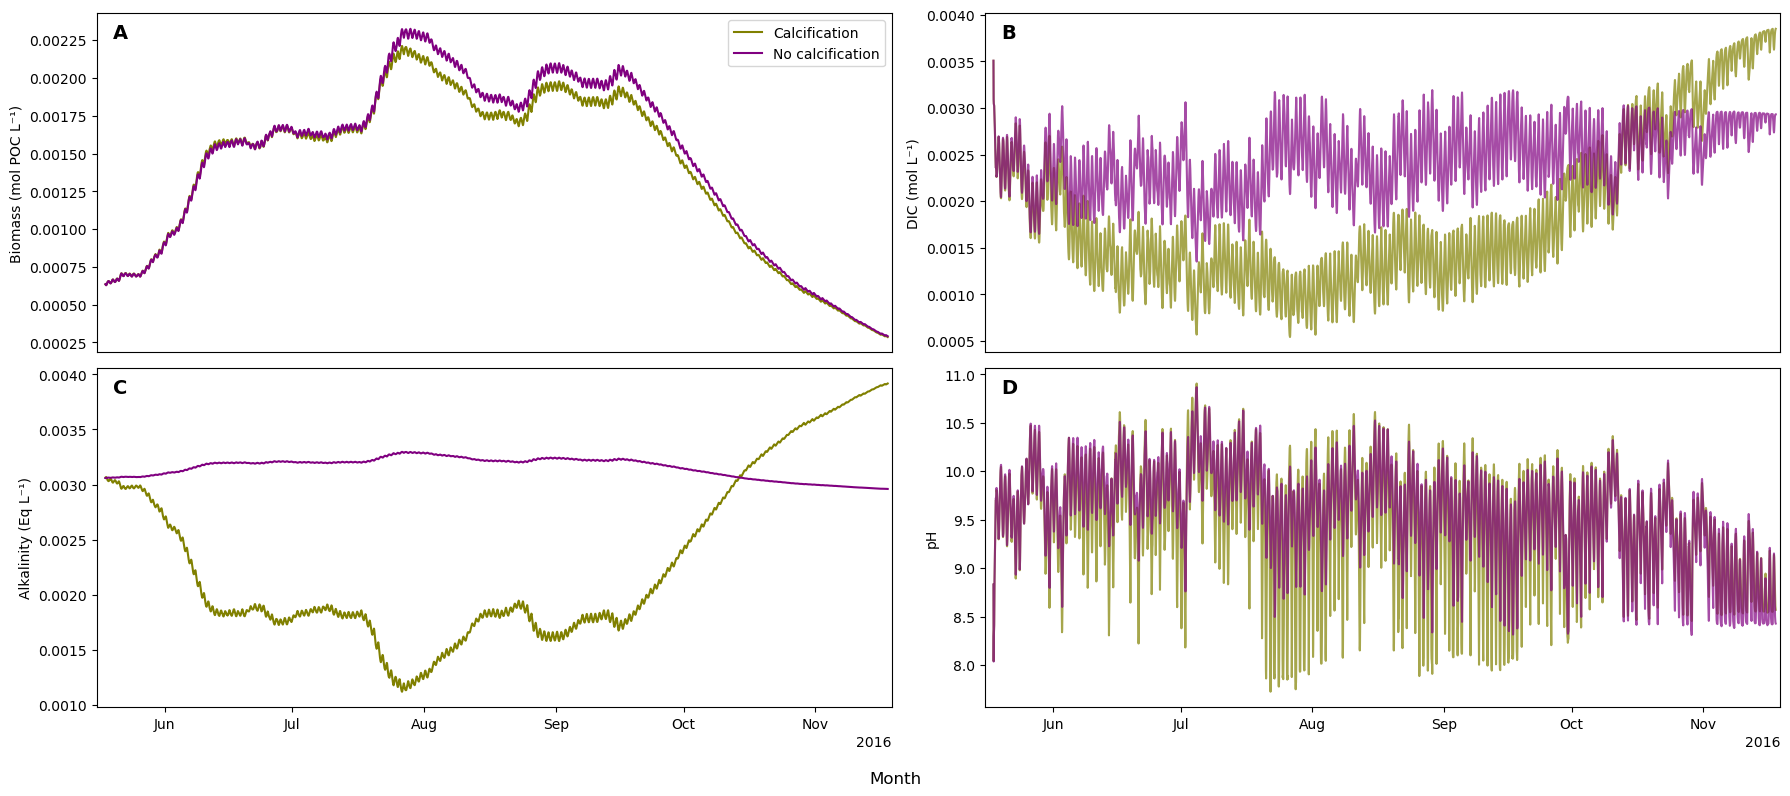

In [9]:
fig, axs = plt.subplots(2,2, figsize=(18, 8))

axs[0,0].plot(df1["date"], df1["B"], color="olive")
axs[0,0].plot(df2["date"], df2["B"], color="purple")
axs[0,0].set_ylabel('Biomass (mol POC L⁻¹)')

axs[0,1].plot(df1["date"], df1['DIC'], color="olive", alpha=0.7)
axs[0,1].plot(df2["date"], df2['DIC'], color="purple", alpha=0.7)
axs[0,1].set_ylabel('DIC (mol L⁻¹)')

axs[1,0].plot(df1["date"], df1['Alk'], color="olive")
axs[1,0].plot(df2["date"], df2['Alk'], color="purple")
axs[1,0].set_ylabel('Alkalinity (Eq L⁻¹)')

axs[1,1].plot(df1["date"], df1['pH'], color="olive", alpha=0.7)
axs[1,1].plot(df2["date"], df2['pH'], color="purple", alpha=0.7)
axs[1,1].set_ylabel('pH')

for ax in axs.flat:
    ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))

locator = mdates.AutoDateLocator()
axs[1,0].xaxis.set_major_locator(locator)
axs[1,0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

axs[1,1].xaxis.set_major_locator(locator)
axs[1,1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

for ax in axs[0, :]:
    ax.tick_params(axis="x", bottom=False, labelbottom=False)

# fig.suptitle("Biomass-calcification model with and without calcification", fontsize=16)
axs[0,0].legend(["Calcification", "No calcification"], loc='upper right')
fig.supxlabel("Month")


for ax, label in zip(axs.flat, "ABCD"):
    ax.text(
        0.02, 0.97, label,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=14, fontweight="bold"
    )
    
plt.tight_layout()

##### Saving #####
out = os.path.join(output_dir, f"Plots\\Bcalc_nocalc_comparison.png")
plt.savefig(out)

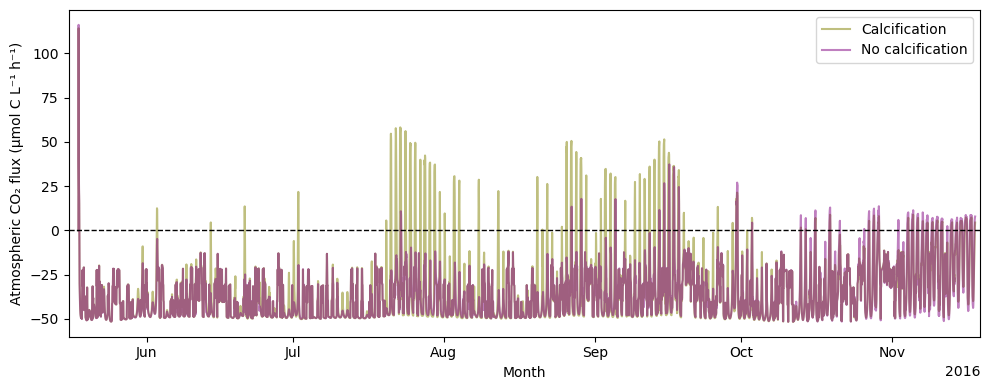

In [19]:
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(df1["date"], df1["CO2_atm"]*-10**6, color="olive", alpha=0.5)
ax.plot(df2["date"], df2["CO2_atm"]*-10**6, color="purple", alpha=0.5)

ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))

locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

# fig.suptitle("Atmospheric CO₂ flux, with and without calcification ", fontsize=16)
ax.legend(["Calcification", "No calcification"], loc='upper right')

ax.set_xlabel("Month")
ax.set_ylabel("Atmospheric CO₂ flux (μmol C L⁻¹ h⁻¹)")

ax.axhline(y=0, color="black", linestyle="--", linewidth=1)

plt.tight_layout()

##### Saving #####
out = os.path.join(output_dir, f"Plots\\co2atmflux_nocalc_comparison.png")
plt.savefig(out)

In [93]:
df1_summer = df1[df1["date"]>"2016-06-10"]
df1_summer = df1_summer[df1_summer["date"]<"2016-09-27"]

df2_summer = df2[df2["date"]>"2016-06-10"]
df2_summer = df2_summer[df2_summer["date"]<"2016-09-27"]

# fig, ax = plt.subplots()
# ax.scatter(df1_summer["date"], df1_summer['B'], s=3, color="steelblue")



In [5]:
df1['B'].max()

np.float64(0.002211213890185274)

In [105]:
print('########### Biomass ###########')
print('calc_max :', np.max(df1['B']))
print('nocalc_max :', np.max(df2['B']))
print('calc summer average: ', np.average(df1_summer['B']))
print('nocalc summer average: ', np.average(df2_summer['B']))

print('')
print('########### DIC ###########')
print('calc_min :', np.min(df1['DIC']))
print('nocalc_min :', np.min(df2['DIC']))
print('calc summer average: ', np.average(df1_summer['DIC']))
print('nocalc summer average: ', np.average(df2_summer['DIC']))

print('')
print('########### Alkalinity ###########')
print('calc_min :', np.min(df1['Alk']))
print('nocalc_max :', np.max(df2['Alk']))
print('calc summer average: ', np.average(df1_summer['Alk']))
print('nocalc summer average: ', np.average(df2_summer['Alk']))

print('')
print('########### pH ###########')
print('calc_max :', np.max(df1['pH']))
print('nocalc_max :', np.max(df2['pH']))
print('calc summer average: ', np.average(df1_summer['pH']))
print('nocalc summer average: ', np.average(df2_summer['pH']))

########### Biomass ###########
calc_max : 0.002211213890185274
nocalc_max : 0.002325068505667731
calc summer average:  0.0017889145404679943
nocalc summer average:  0.0018650537945105734

########### DIC ###########
calc_min : 0.0005439236033764175
nocalc_min : 0.001353218878339334
calc summer average:  0.0013049315751716929
nocalc summer average:  0.0023769842494488803

########### Alkalinity ###########
calc_min : 0.001121318877146663
nocalc_max : 0.003296501522770781
calc summer average:  0.001723634411815573
nocalc summer average:  0.003222083399210703

########### pH ###########
calc_max : 10.90448948860091
nocalc_max : 10.8667339894539
calc summer average:  9.533631212015415
nocalc summer average:  9.719642208481076


np.float64(0.0017889145404679943)

1 June–31 August